# Season by season, and upsets

Plain Elo on every season from 2015-16 to 2021-22 (2014-15 is Elo's burn-in). Elo only ever uses games before each prediction, so every season here is out of sample for the rating itself. Its three settings were tuned on 2015-16 to 2019-20, though. **The test seasons (2022-23 to 2024-25) stay sealed until day 10.**

In [1]:
import os
from pathlib import Path

os.environ.setdefault("NBA_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nba_predictor.ablation import EloRestAdjustment
from nba_predictor.evaluate import per_season, split, wilson
from nba_predictor.train import matrix

feats = pd.read_parquet(Path(os.environ["NBA_DATA_DIR"]) / "processed" / "features.parquet")
train, validation, _ = split(feats)
dev = pd.concat([train, validation])
dev = dev[dev["season"] != "2014-15"].copy()
adjust = EloRestAdjustment().fit(matrix(train), train["home_win"])
dev["adjusted"] = adjust.predict_proba(matrix(dev))[:, 1]
seasons = per_season(dev, "elo_prob")
seasons["adjusted log loss"] = per_season(dev, "adjusted")["log_loss"]
seasons.round(4)

,games,log_loss,low,high,accuracy,predicted,won,adjusted log loss
season,,,,,,,,
2015-16,1230,0.5838,0.5617,0.6034,0.6951,0.5740,0.5886,0.5824
2016-17,1230,0.6222,0.6014,0.6417,0.6463,0.5734,0.5837,0.6200
2017-18,1230,0.6161,0.5983,0.6347,0.6577,0.5775,0.5789,0.6140
2018-19,1230,0.6142,0.5946,0.6361,0.6423,0.5726,0.5927,0.6113
2019-20,1059,0.6274,0.6067,0.6479,0.6506,0.5624,0.5515,0.6268
2020-21,1080,0.6480,0.6271,0.6663,0.6194,0.5765,0.5435,0.6465
2021-22,1230,0.6351,0.6130,0.6551,0.6504,0.5783,0.5439,0.6329


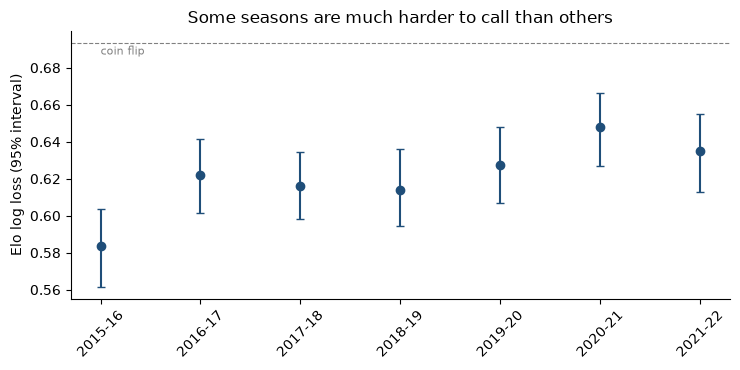

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(seasons))
ax.errorbar(
    x,
    seasons["log_loss"],
    yerr=[seasons["log_loss"] - seasons["low"], seasons["high"] - seasons["log_loss"]],
    fmt="o",
    color="#1f4e79",
    capsize=3,
)
ax.axhline(np.log(2), color="grey", lw=0.8, ls="--")
ax.text(0, np.log(2) - 0.006, "coin flip", fontsize=8, color="grey")
ax.set_xticks(x, seasons.index, rotation=45)
ax.set_ylabel("Elo log loss (95% interval)")
ax.set_title("Some seasons are much harder to call than others")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/elo_by_season.png", dpi=150)

- **The season matters more than the model.** Elo's log loss runs from 0.584 (2015-16) to 0.648 (2020-21), and one season's interval is about ±0.02 wide. Day 7 and 8's model differences were about 0.002.
- **2020-21 was the hardest season** (0.648, 61.9% right): shortened, with empty arenas, many games missed under health protocols, and the weakest home edge.
- **The back-to-back adjustment has a lower log loss than plain Elo in all 7 seasons,** but it was fitted on 2014-15 to 2019-20, so only 2020-21 and 2021-22 are fair for it. Day 10's test seasons decide.

## Are Elo's favourites as safe as it says?

In [3]:
fav = np.maximum(dev["elo_prob"], 1 - dev["elo_prob"])
fav_won = np.where(dev["elo_prob"] >= 0.5, dev["home_win"], 1 - dev["home_win"])
dev = dev.assign(fav=fav, fav_won=fav_won)
rows = []
for low, high in [(0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 1.0)]:
    g = dev[(dev["fav"] >= low) & (dev["fav"] < high)]
    lo, hi = wilson(int(g["fav_won"].sum()), len(g))
    rows.append(
        {
            "Elo favourite": f"{low:.0%}-{high:.0%}",
            "games": len(g),
            "predicted": g["fav"].mean(),
            "won": g["fav_won"].mean(),
            "95%": f"{lo:.3f} to {hi:.3f}",
        }
    )
pd.DataFrame(rows).set_index("Elo favourite").round(3)

,games,predicted,won,95%
Elo favourite,,,,
50%-60%,2936,0.550,0.541,0.523 to 0.559
60%-70%,2587,0.648,0.650,0.632 to 0.668
70%-80%,1826,0.747,0.735,0.714 to 0.755
80%-100%,940,0.844,0.845,0.820 to 0.866


Across the board, yes: each band's favourites won within about 1 point of what Elo said. An upset is a game Elo gave a favourite 70% or more and the favourite lost. Where do they cluster?

In [4]:
big = dev[dev["fav"] >= 0.7]
fav_home = (big["elo_prob"] >= 0.5).to_numpy()
fav_b2b = np.where(fav_home, big["home_b2b"], big["away_b2b"])
dog_b2b = np.where(fav_home, big["away_b2b"], big["home_b2b"])
early = (big[["home_games_played", "away_games_played"]].min(axis=1) < 10).to_numpy()
cases = {
    "favourite on a back-to-back, underdog rested": (fav_b2b == 1) & (dog_b2b == 0),
    "underdog on a back-to-back, favourite rested": (dog_b2b == 1) & (fav_b2b == 0),
    "neither on a back-to-back": (fav_b2b == 0) & (dog_b2b == 0),
    "either team in its first 10 games": early,
    "both past 10 games": ~early,
    "favourite at home": fav_home,
    "favourite away": ~fav_home,
}
rows = []
for name, m in cases.items():
    g = big[m]
    lo, hi = wilson(int(g["fav_won"].sum()), len(g))
    rows.append(
        {
            "case": name,
            "games": len(g),
            "predicted": g["fav"].mean(),
            "won": g["fav_won"].mean(),
            "95%": f"{lo:.3f} to {hi:.3f}",
        }
    )
pd.DataFrame(rows).set_index("case").round(3)

,games,predicted,won,95%
case,,,,
"favourite on a back-to-back, underdog rested",311,0.780,0.733,0.681 to 0.779
"underdog on a back-to-back, favourite rested",455,0.783,0.824,0.787 to 0.856
neither on a back-to-back,1867,0.780,0.763,0.743 to 0.782
either team in its first 10 games,324,0.774,0.716,0.665 to 0.762
both past 10 games,2442,0.781,0.780,0.763 to 0.796
favourite at home,2185,0.785,0.775,0.757 to 0.792
favourite away,581,0.762,0.762,0.726 to 0.795


## Findings

1. **Elo's probabilities hold up overall,** within about 1 point in every band of favourite.
2. **Upsets cluster where Elo has no information.**
   - **Back-to-backs:** a big favourite on a back-to-back against a rested underdog won 73.3% against 78.0% predicted. When the underdog was the tired one, the favourite won 82.4% against 78.3%. That's the day 5 effect again, and what the adjustment captures.
   - **The start of the season:** in teams' first 10 games, big favourites won 71.6%, below the 77.4% Elo said, with an interval (66.5% to 76.2%) that just misses it. Elo carries 80% of last season's rating into the next, so a summer of trades and injuries isn't priced in. A lower carry-over would trade this against a worse middle of the season; day 5's tuning chose 0.8 on overall log loss.
3. **Away favourites are as reliable as home ones** (76.2% predicted, 76.2% won).

These are the README's main limitations: no information about who is playing, and a rating that's slow to see roster changes.